> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/rhine.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Inland waterways in Germany

[Specific trades](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/specific-trades.html) · deck `simulations/examples/example_6/`

What e-fuel price and CO2 price lead fleet owners and operators to switch fuel?

## The case

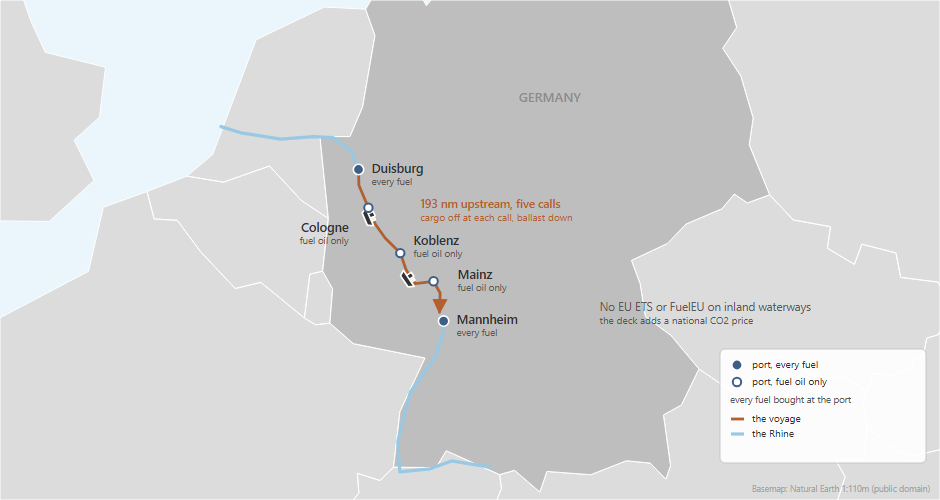

- **Ships:** 300 large Rhine motor cargo vessels, all on fuel oil in 2026. The
  library has no inland vessel, so the ship is a library general cargo ship
  resized for the Rhine (INVENTED). The owners can burn a drop-in fuel (FAME,
  e-diesel) in the ships they have, or order LNG or methanol ships.
- **Route:** one route up the Rhine, Duisburg, Cologne, Koblenz, Mainz and
  Mannheim, a quarter of the cargo discharged at each call, then back to
  Duisburg in ballast.
- **Fuels:** fuel oil at every port; LNG, FAME, e-diesel and e-methanol at
  Duisburg and Mannheim only. Every fuel is bought at the port at a set price,
  plus a handling cost (INVENTED). The prices and upstream emissions of FAME and
  the e-fuels are placeholders for your source: by default what the library's
  own plants would cost, FAME 45 USD/GJ and e-diesel 103 USD/GJ in 2026 to 71 by
  2050, against about 12 for fuel oil.
- **Policy:** Germany's national CO2 price, 65 USD/t in 2026 to 150 in 2050
  (INVENTED), as a copy of the library's EU ETS on the five ports; the
  CO2_PRICE lever below changes it, and 0 removes it. EU ETS and FuelEU do not
  cover inland waterways.
- **Horizon:** 2026 to 2050, yearly.

## Results

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_6")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


Moved up to the repository root.
Navigate 1.0.0 is already installed.


The cell below solves the case from 2026 to 2050 and draws its well-to-wake emissions, its freight rate and the fuel it burns.

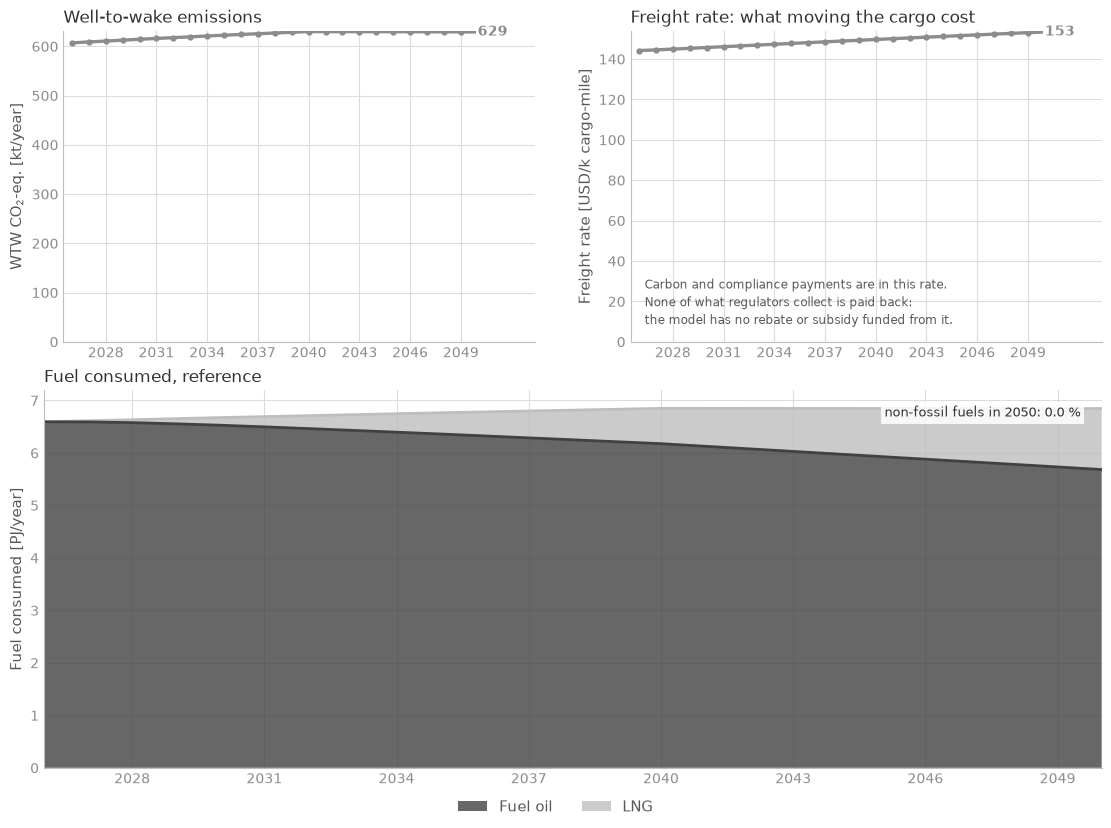

In [2]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare_with_previous, plot_cases, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_6/example_6.nav")
REF_TWEAK = None
_m = run_case(NAV)
ref = summarise(_m)
plot_cases({"reference": ref}, annotate=True)
plt.show()


# ===========================================================================
#  The machinery for the sensitivity analysis. Nothing to edit here: the
#  levers are further down.
# ===========================================================================
# each lever, and the forecasts it multiplies
LEVERS = {
    "OIL_PRICE": ['fossil_fuel_oil_price_global'],
    "LNG_PRICE": ['liquefied_natural_gas_price_global'],
    "CO2_PRICE": ['germany_co2_price'],
    "E_DIESEL_PRICE": ['rhine_e_diesel_price'],
    "E_METHANOL_PRICE": ['rhine_e_methanol_price'],
    "FAME_PRICE": ['rhine_fame_price'],
    "HULL_PRICE": ['rhine_hull_capex'],
}
_RUNS = []      # the scenarios solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Solve the levers set in the YOUR SCENARIO cell and compare with
    the reference and with the scenario solved before it."""
    changed = [(n, globals()[n]) for n in LEVERS if globals()[n] != 1.0]
    if not changed:
        print("Every lever is still at 1.0, so this would just re-solve the deck.")
        print("Change one of the numbers above and run this cell again.")
        return
    tweaks = ([REF_TWEAK] if REF_TWEAK else []) + [scale(f, v) for n, v in changed
                                                   for f in LEVERS[n]]

    def your_scenario(m):
        for t in tweaks:
            t(m)

    label = ",  ".join(f"{n} x {v}" for n, v in changed)
    compare_with_previous(NAV, ref, your_scenario, label, _RUNS, ref_label="reference")
    plt.show()


### Move one lever

Each number multiplies what the deck already says, so 1.0 is the reference. Set one, run the cell, and compare with the reference and with the scenario you ran before. As an example, E_DIESEL_PRICE is set to 0.2: e-diesel at a fifth of the deck's price.

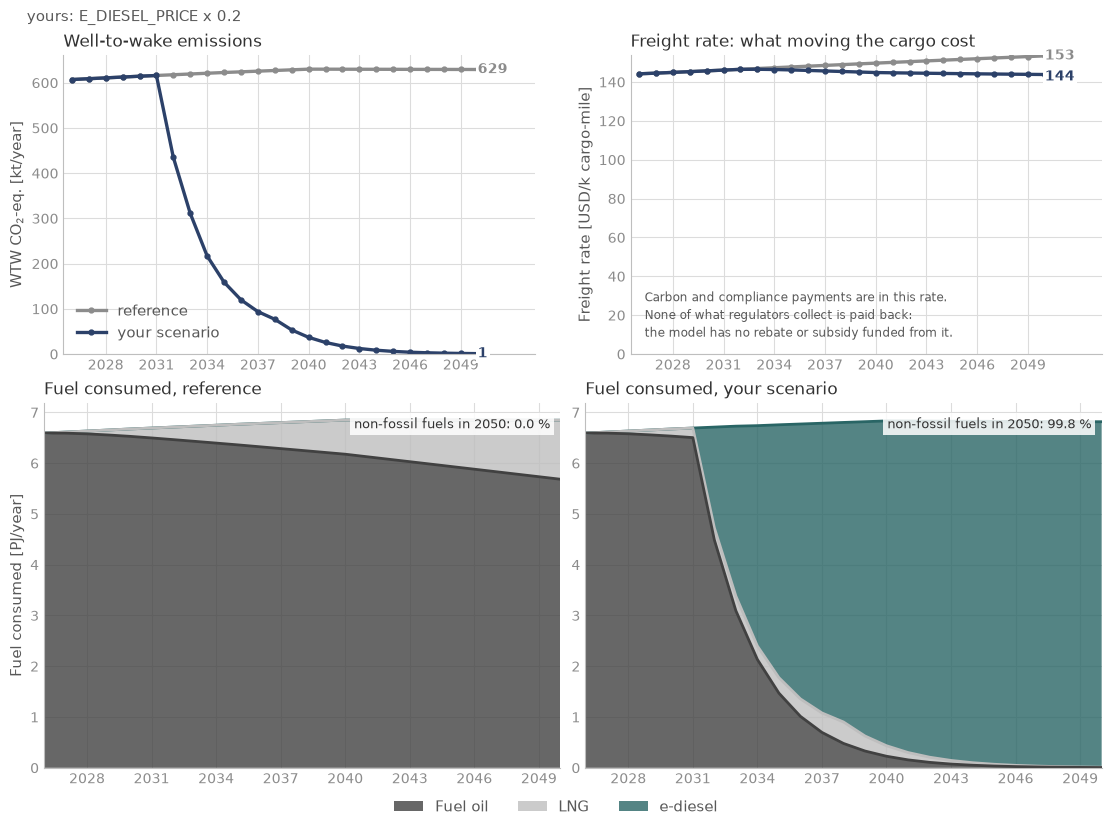

In [3]:
# ===========================================================================
#  YOUR SCENARIO.  Set a lever, then run this cell: it solves your scenario
#  and compares it with the reference and with the scenario you ran before it.
#
#  Every number is a MULTIPLIER on what the deck already says, so 1.0 is the
#  deck. The right-hand column says what each 1.0 is worth, so you can judge
#  whether a factor of two is a big change or a small one.
#
#  As an example, E_DIESEL_PRICE is set to 0.2: e-diesel at a fifth of the deck's price.
#  Set E_DIESEL_PRICE back to 1.0 to start from the deck.
#
#                           suggested span  what 1.0 means in the deck
OIL_PRICE        = 1.0   #  0.7 - 2.0       485 USD/t (11.8 USD/GJ), flat to 2050
LNG_PRICE        = 1.0   #  0.7 - 1.6       436 USD/t (8.7 USD/GJ), flat to 2050
CO2_PRICE        = 1.0   #  0.0 - 10.0      65 USD/t CO2 in 2026, 150 by 2050 (INVENTED); 0.0 = no CO2 price
E_DIESEL_PRICE   = 0.2   #  0.1 - 1.0       103 USD/GJ in 2026, 71 by 2050
E_METHANOL_PRICE = 1.0   #  0.1 - 1.0       84 USD/GJ in 2026, 57 by 2050
FAME_PRICE       = 1.0   #  0.2 - 1.0       45 USD/GJ, flat to 2050
HULL_PRICE       = 1.0   #  0.5 - 2.0       6 M USD for the hull (INVENTED)
# ===========================================================================

run_your_scenario()


## The deck

In [4]:
# @title The deck, tab by tab
import sys
from pathlib import Path

sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _deck import show_deck

show_deck(EXAMPLE, {
    "The deck": ['example_6.nav'],
    "Placeholders": ['includes/placeholders.inc'],
    "Fleet": ['includes/fleet.inc'],
    "Route": ['includes/route.inc'],
    "Fuels and ports": ['includes/fuels.inc', 'includes/ports.inc', 'includes/bunker_logistics.inc'],
    "CO2 price": ['includes/co2_price.inc'],
    "Decision processes": ['includes/calibration.inc'],
    "Report": ['includes/report.inc'],
})


# ---- example_6.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# RHINE INLAND DRY CARGO, Duisburg - Mannheim, 2026-2050, yearly steps.
# One deck, with Germany's national CO2 price (includes/co2_price.inc); set its
# Forecast to 0 for no policy. EU ETS and FuelEU Maritime do not cover inland
# waterways, so DefaultRegulation is not loaded.
#
# Ships: built from the library's general cargo vessels (general_cargo_ice_oil,
# _ice_methane, _ice_methanol) and resized for the Rhine. The fuel-system and tank
# costs are a seagoing ship's. No ammonia ships. No fuel conversion.
# AllowSpeedManagement is FALSE: the waterway sets the speed.
# DefaultConverterAvailable is not loaded (it needs the library's 23 fleets), so
# every vessel type is orderable from year one rather than phased in.
#
# INVENTED placeholders (Variables/Curves/Forecasts in includes/placeholders.inc;
# plain numbers in includes/route.inc):
#   - 300 ships in 2026, aged evenly 0-39 years
#   - 3,000 t capacity, 40-year lifetime, 6 M USD hull newbuild price, 1.5 MW propulsion
#   - propulsion power vs speed: 4 kn 0.25, 6 kn 0.6, 8 kn 1.1, 9 kn 1.45 MW
#   - auxiliary 0.1 MW at sea, 0.05 MW in port, 0.2 MW generators
#   - route distances 50/52/51/40/193 nm, speeds 7 kn up and 8 kn back,
#     1 day in port, loads 1.0/0.75/0.5/0.25/0
#   - handling at the ports, USD/t: fuel oil, FAME and e-diesel 10, LNG 40, e-methanol 15
#   - CO2 price 65 USD/t (2026) to 150 USD/t (2050)
# PLACEHOLDERS for your source (includes/placeholders.inc), defaults from the library's
# own plants in this deck: FAME 45 USD/GJ, flat, about a quarter of fuel oil's CO2;
# e-diesel 103 USD/GJ (2026) to 71 (2050) and e-methanol 84 to 57, both net zero.
# All five fuels are market fuels bought at the ports; nothing is made in the deck.

DEFINE {
	Load DefaultModelDefinition

	Include "includes/placeholders.inc"

	# ---- fleet and route ----
	Include "includes/fleet.inc"
	Include "includes/route.inc"
	Include "includes/ports.inc"
	Include "includes/bunker_logistics.inc"

	# ---- fuel ----
	Include "includes/fuels.inc"
	Load DefaultEmission

	# ---- policy: Germany's CO2 price ----
	Include "includes/co2_price.inc"

	# ---- decision processes ----
	Include "includes/calibration.inc"

	# ---- export ----
	Include "includes/report.inc"
	Load DefaultReport
	Load DefaultPlot
}

EVENTS {
	Load DefaultTimeStepYearly
}

# ---- includes/placeholders.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# PLACEHOLDERS - every INVENTED or GIVEN number of this case that can be a
# Variable, Curve or Forecast, in one place. Replace them here.
#
# Plain numbers that Navigate takes only as numbers live in their own file:
#   includes/route.inc             distances, speeds, port days, loads   (INVENTED)

# ---- fleet (INVENTED) -------------------------------------------------------
Variable "rhine_initial_vessels" {
	Value = 300            # INVENTED: ships in 2026
}

Curve "rhine_age_dist" {
	# INVENTED: ships aged evenly from 0 to 39 years (1/40 each)
	Table = [
		0	0.025
		1	0.025
		2	0.025
		3	0.025
		4	0.025
		5	0.025
		6	0.025
		7	0.025
		8	0.025
		9	0.025
		10	0.025
		11	0.025
		12	0.025
		13	0.025
		14	0.025
		15	0.025
		16	0.025
		17	0.025
		18	0.025
		19	0.025
		20	0.025
		21	0.025
		22	0.025
		23	0.025
		24	0.025
		25	0.025
		26	0.025
		27	0.025
		28	0.025
		29	0.025
		30	0.025
		31	0.025
		32	0.025
		33	0.025
		34	0.025
		35	0.025
		36	0.025
		37	0.025
		38	0.025
		39	0.025
	]
}

Variable "rhine_nominal_capacity" {
	Value = 3000           # INVENTED: t per ship
}

Variable "rhine_lifetime" {
	Value = 40             # INVENTED: years
}

Forecast "rhine_hull_capex" {
	# INVENTED: 6 M USD newbuild price for the hull
	Table = [
		"01-01-2025"	6e6
		"01-01-2050"	6e6
	]
}

Variable "rhine_propulsion_power_capacity" {
	Value = 1.5    

## Build it with an AI assistant

This deck was built from the prompt below by an assistant that saw only the
prompt. A trade under a national policy starts from it.
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows how to use it.

<details>
<summary>Full prompt for this case</summary>

<!-- tested-prompt: a8eb5946672f -->
**The study.** Dry-cargo motor vessels on the Rhine between Duisburg and
Mannheim, 2026 to 2050, in one deck with a CO2 price on the fossil fuel they
burn, standing for Germany's national CO2 price; setting the price to 0 gives
the case without policy. The price is a copy of the library's EU ETS regulation
moved to the two German ports, so only its price path is invented. Every fuel is bought at the bunker ports at a set
price, like fuel oil; the prices and upstream emissions of FAME, e-diesel and
e-methanol are taken from a source outside Navigate. The question is what e-fuel
price and CO2 price lead fleet owners and operators to switch fuel: to e-diesel
or biodiesel in the ships they have, or to new engines.

**What comes from the library.** The engines, tanks and fuel options of the
library's general cargo ships, and the fuels and their prices.

**What is INVENTED.** The library has no inland vessel, so the ship is a library
general cargo ship resized for the Rhine: its capacity, power, propulsion curve,
price and lifetime are placeholders. The route, fleet size, handling costs at the
ports and the CO2 price path are invented too. The FAME and e-fuel prices and
upstream emissions are placeholders for your own source; their defaults are what
the library's own plants would cost and emit in this deck. Replace the
placeholders with sourced data before quoting any result.

**Limits.** Navigate has no river current, locks or low-water periods, and no
battery-electric ship, which is one of the options German inland operators are
actually weighing.

**Tested:** 2026-10-16. The final prompt passed every check above on the first
attempt, built cold and also through Session 5's start-up prompt from a different
inland case (container barges from Duisburg to Frankfurt). Three earlier rounds
found the traps now written in `building-a-deck.md`. Both builds found that at 65
to 150 USD/t the owners pay the price rather than switch fuel, and order a few
more LNG ships; the drop-in fuels need roughly 440 USD/t (biodiesel) to 800-1,100
USD/t (e-diesel). Treat that as a property of the placeholders, not of the Rhine.
2026-10-26, as the model a start-up prompt chose for a different case (Norwegian coastal cargo ships and ferries under Norway's CO2 tax): the chain built and ran cold with no warnings, and found the same: biofuels need roughly 440 USD/t, and the owners pay the tax, order a few more LNG ships and slow down.
2026-10-30, with the route's five ports (before, it ran between Duisburg and
Mannheim only): built cold on Sonnet and on Haiku, both decks ran with no
warnings, and the two builds agree to the tonne. Same finding: by 2050 the price
moves about two newbuilds to LNG and emissions by less than 0.01 %; FAME would
need about 430 USD/t. The Sonnet build was the deck in
`simulations/examples/example_6/`.
2026-11-04, changed so that e-diesel and e-methanol are bought at the ports at a
set price, as market fuels, instead of made by the library's plants, and the
question became what e-fuel price and CO2 price make the owners switch: built
cold on Sonnet and on Haiku, both decks ran with no warnings, and the two builds
agree to the tonne with each other and with the deck in
`simulations/examples/example_6/`, which was changed by hand to match (607 kt
in 2026, 629 kt in 2050). At the deck's e-fuel prices no e-fuel is used;
e-diesel takes over below about 18 USD/GJ in 2030 and 23 USD/GJ in 2050, fuel
oil's 11.8 plus the CO2 price. Both builds found for themselves that Region
"europe" needs Source "renewable" imported, and both read the e-fuel
well-to-tank line as intended; its wording was made plainer afterwards.
2026-11-04 again, changed so that FAME too is bought at a set price (every fuel
is a market fuel, nothing is made in the deck, so the deck has no region or
producer and restates DefaultCalibration's Port and Fleet blocks), with
INVENTED handling costs at the ports, and the question names fleet owners and
operators: built cold on Sonnet (first time) and on Haiku, both decks ran with
no warnings, and both builds agree to the tonne with each other and with the
deck (607,103 t in 2026; 629,307 and 629,328 t in 2050). E-diesel takes over
below about 17-18 USD/GJ in 2030 and 22-23.5 USD/GJ in 2050, handling included;
at the deck's prices FAME needs about 440 USD/t of CO2, e-methanol about 600 and
e-diesel about 780 by 2050. Haiku took the library's fame_wtt_carbon_dioxide
(0.627, per t of feedstock, without the biogenic credit) for a contradiction of
the FAME line, which now says how the two relate. Haiku had to put Port "*"
after the named ports.


It was one of Session 5's examples until 2026-10-28.

````text
You are helping me build a simulation study for Navigate, the shipping
decarbonisation model. Write the files yourself; do not only
describe them.

Before writing anything, find the Navigate repository on my machine (a folder
usually named navigate-zcs; ask me where it is if you cannot find it), then read
docs/workshop/building-a-deck.md in it and follow it. It
says how Navigate works, how to run a deck and read its results, and the rules
every deck follows. This prompt gives the case.

THE DECK
A new folder, simulations/user/rhine_inland/, holding one deck, rhine.nav, with
Germany's CO2 price in includes/co2_price.inc. Keep the price path in one
Forecast, so that setting it to 0 gives the case without policy.

THE CASE
Inland dry-cargo shipping on the Rhine within Germany, 2026 to 2050, yearly steps.
- Fleet: large Rhine motor cargo vessels, all on fuel oil at the start. The
  owners can keep their ships, burn a drop-in fuel in them, or order ships with
  LNG or methanol engines. No ammonia ships: they are not realistic on inland
  waterways.
- Trade: one route up the Rhine with five ports called in this order, Duisburg,
  Cologne, Koblenz, Mainz and Mannheim, then straight back to Duisburg. The ships
  load at Duisburg and discharge part of the cargo at each call upstream; they
  return in ballast.
- Fuels: every fuel is bought at the bunker ports at a set price, and none is
  made in the deck: fuel oil and LNG at their library prices; biodiesel (FAME)
  and e-diesel, which burn in the oil engines, and e-methanol, at the placeholder
  prices below.
- Policy: EU ETS and FuelEU Maritime do not cover inland waterways, so do not
  load DefaultRegulation. The deck adds Germany's national CO2 price as a copy
  of the library's EU ETS regulation:
  Copy Regulation "eu_ets" to "co2_price_germany", with its Jurisdiction set to
  the five ports and its RemedialCost set to the CO2 price below. Keep the rest of
  it: it already counts biofuels and e-fuels as zero CO2. It names fuels this case
  does not use (bio-methanol, bio-methane, e-methane, blue and e-ammonia), so
  import those too, or it will not parse. building-a-deck.md says
  why this is a Regulation and not a Levy.

HOW TO BUILD IT
The library has no inland vessel. Build the ships from the library's general
cargo vessels (general_cargo_ice_oil, _ice_methane, _ice_methanol) with Copy
Vessel, and resize them for the Rhine with the placeholder values below. A
vessel's engine power sits in its Converter nodes, which its PowerSystem names,
so give each copied vessel its own copies of those, with the new power. Keep the
library's tanks, fuel options and machinery costs, and say in the .nav header
that the fuel-system and tank costs are a seagoing ship's. Ships cannot be
converted to another fuel: leave the library's set_fuel_conversion_cost out. Set
AllowSpeedManagement = FALSE: on a river the waterway sets the speed, and with it
on, the ships drift faster than the speeds below.

Build the rest as building-a-deck.md describes for a deck on named ports: the
Fleet node, one ROUND_TRIP route through your own ports duisburg, cologne,
koblenz, mainz and mannheim, in that order, with five legs (the last one
mannheim back to duisburg), the ports and what each one sells, and the bunker
logistics. Nothing is made in the deck, so it has no region, plant or producer:
list all five fuels in the bunker logistics' LiquidMarketFuels, and at the ports
give FAME, e-diesel and e-methanol each a set_bunker_price_overwrite and a
set_bunker_wtt_overwrite (carbon_dioxide, and methane for FAME) from the
placeholders below, as the ports do for fuel oil. Give every fuel a
set_handling_cost at the ports, from the placeholders.

NUMBERS
Everything not listed here comes from the library, by name. These are
placeholders, INVENTED for this case: mark each one where it appears, list them
all in both .nav headers, and keep them in one file, includes/placeholders.inc,
as Variables, Curves and Forecasts, so a user can replace them in one place. The
route takes plain numbers only: write those in its own file, marked INVENTED,
and list them in placeholders.inc as comments.
- Fleet: 300 ships in 2026, aged evenly from 0 to 39 years, so about one in
  forty retires each year
- Ship: 3,000 t capacity, 40-year lifetime, 6 M USD newbuild price for the hull,
  1.5 MW propulsion power
- Propulsion power at speed, MW: 4 kn 0.25, 6 kn 0.6, 8 kn 1.1, 9 kn 1.45
- Auxiliary power: 0.1 MW at sea and 0.05 MW in port, with 0.2 MW generators
  (the library's are a seagoing ship's)
- Route: Duisburg to Cologne 50 nm, Cologne to Koblenz 52 nm, Koblenz to Mainz
  51 nm, Mainz to Mannheim 40 nm, Mannheim back to Duisburg 193 nm; 7 kn on the
  four legs upstream, 8 kn on the way back (speed through the water; Navigate
  has no river current); one day in port per call
- Load: 1.0, 0.75, 0.5 and 0.25 full on the four legs upstream (a quarter of
  the cargo discharged at each of Cologne, Koblenz and Mainz), 0 on the way back
- Bunkering: fuel oil at every port; LNG, FAME, e-diesel and e-methanol at
  duisburg and mannheim only
- Handling at the ports, USD per t of fuel: fuel oil, FAME and e-diesel 10,
  LNG 40, e-methanol 15
- CO2 price: 65 USD per t CO2 in 2026, rising linearly to 150 USD in 2050

The FAME and e-fuel numbers below are not INVENTED: they are what the
library's own plants would cost and emit in this deck, delivered to the port.
Mark them as placeholders for the user's own source.
- FAME price at the bunker ports, USD per t, linear between the points: 1,669
  in 2026, 1,667 in 2030, 1,663 in 2040, 1,659 in 2050
- FAME upstream (well-to-tank), per t of fuel: -2.086, -2.103, -2.130 and
  -2.139 t CO2 in the same years, and 0.0016 t methane. These include the
  biogenic credit: -2.84 t for the CO2 the oil's crops took up, plus about 0.75 t
  from processing (the library's fame_wtt_carbon_dioxide, 0.627 per t of
  feedstock, plus grey methanol and grid power). Not net zero: its tailpipe CO2
  is 2.84 t, so about 0.75 t per t remains.
- E-fuel prices at the bunker ports, USD per t, linear between the points:
  e-diesel 4,390 in 2026, 4,023 in 2030, 3,369 in 2040, 3,019 in 2050;
  e-methanol 1,680, 1,512, 1,260 and 1,132.
- E-fuel upstream (well-to-tank) CO2, t per t of fuel: -3.206 for e-diesel and
  -1.38 for e-methanol. These are the library's tailpipe CO2 of each fuel with
  the sign changed, so upstream and tailpipe cancel (net zero).

BEFORE YOU TELL ME IT WORKS
Run the deck and report on it as building-a-deck.md says. Then give me:
- the share of energy by fuel in 2026, 2035 and 2050;
- the fleet's well-to-wake emissions in 2026 and 2050, and summed over 2026-2050;
- the ships of each kind in 2050, and what the CO2 price cost the owners
  (RegulationExpenses).
Say plainly whether the owners switched fuel: drop-in fuel in the ships they
have, new engines, both, or nothing. Then answer the case's question from the bunker
prices, handling included: roughly what e-fuel price, in USD per GJ, makes the
owners and operators switch at the deck's CO2 price in 2030 and in 2050, and
roughly what CO2 price makes them switch at the deck's FAME and e-fuel prices.
Remind me which inputs are placeholders.
````

</details>

### Variant

<details>
<summary>Coastal shipping in Norway: two ship classes under a national CO2 tax</summary>

**Variant of "Inland waterways in Germany" above**, with seagoing library
classes instead of a resized vessel, and two classes on one trade. Coastal cargo
ships and ferries between Bergen and Tromsø, 2026 to 2050, owned by many
companies, in one deck with Norway's CO2 tax on domestic shipping; setting the
tax to 0 gives the case without policy. As in the model, every fuel is bought
at the ports at a set price. The question is what biofuel and e-fuel price and
CO2 tax lead fleet owners and operators to switch fuel: to biofuels in the
ships they have, or to new ships.

**Build it from the full prompt of "Inland waterways in Germany", with these differences:**
- Folder `simulations/user/norway_coastal/`, one deck, `norway.nav`, with the
  tax in `includes/co2_tax.inc` and its price path in one Forecast.
- Fleets: two Fleet nodes with Copy Vessel, nearly all on fuel oil at the start:
  100 general cargo ships and 50 ferries (INVENTED), each with its library split
  of designs, age profile and TradeGrowth. Designs oil, LNG and methanol for
  both; leave out the general cargo ammonia design (and its split and age
  entries; its initial share is 0). Neither class has
  `set_fuel_conversion_cost` lines, so no ship can be converted: say so rather
  than invent costs. Keep AllowSpeedManagement as the library sets it (FALSE for
  ferries, TRUE for general cargo). Leave the orderbooks out.
- Route: one ROUND_TRIP between bergen and tromso, 650 nm each way (INVENTED),
  cargo both ways, with one Route node per class: ferries at 14 kn, 0.75 full,
  0.5 x 365 / 50 = 3.65 days per call; general cargo at 11.2 kn, 0.5 full,
  0.452 x 365 / 20 = 8.25 days per call (from each operational profile).
- Fuels: as in the model, every fuel is bought at the ports at a set price and
  none is made in the deck, so it has no region, plant or producer: fuel oil and
  LNG at their library prices; FAME, bio-methane (it burns in the LNG engines),
  bio-methanol and e-methanol at the placeholder prices below. Both ports sell
  every fuel.
- Policy: `co2_tax.inc` copies the library's `eu_ets` to `co2_tax_norway`, with
  the two ports as Jurisdiction and the tax as RemedialCost: 100 USD/t CO2 in
  2026, rising linearly to 200 in 2030, then flat (INVENTED). Import the fuels it
  names that the case does not use (e-diesel, e-methane, blue and e-ammonia).
  Give the price Forecast a name of its own. No DefaultRegulation.
- Handling at the ports, USD per t of fuel (INVENTED): fuel oil and FAME 10,
  LNG and bio-methane 40, bio-methanol and e-methanol 15.
- Placeholders for the user's own source, not INVENTED: what the library's own
  plants in Europe would cost and emit, delivered to the port (the prices
  already include 12 USD/t for it), USD per t, linear between 2026, 2030, 2040
  and 2050. FAME and e-methanol: the model's
  prices and upstream emissions. Bio-methane: 1,480, 1,455, 1,400 and 1,349; upstream
  CO2 -2.617, -2.725, -2.902 and -3.013 t per t, and methane 0.0095, 0.0022,
  -0.0038 and -0.0069 t per t (its tailpipe CO2 is 2.75 t). Bio-methanol, from
  gasified biomass: 890, 870, 811 and 759; upstream CO2 -1.241, -1.273, -1.321
  and -1.348 t per t (its tailpipe CO2 is 1.38 t).
- A Report per fleet (ConsumedEnergy by fuel, ExistingVessels per vessel,
  TotalEquivalentWTW, RegulationExpenses), and the tax's own remedial,
  flexibility and surplus lines in `co2_tax.inc`. Report each fleet and both
  together; say whether new methanol ships burn methanol or their pilot oil.

**Limits.** The ships and their operating patterns are the library's world
averages for the class, not Norwegian coastal vessels. The library has no
battery-electric ships, which much of Norway's ferry fleet is moving to.

**Tested:** 2026-10-26, written by Session 5's start-up prompt from a short case
(it took inland Germany as the model), then built cold: both decks ran with no
warnings. Biofuels need roughly 440 USD/t; at 200 USD/t the owners pay the tax,
order slightly more LNG ships, and the cargo ships slow down, which gives most
of the 4.5 % cut in emissions. The full prompt that passed is in the repository's history, commit `02d96755`. Folded into a variant on 2026-10-28: not yet built from the variant.
2026-11-04, changed as its model was: one deck, every fuel bought at a set
price, INVENTED handling costs. Built cold on Haiku from the model and this
variant: the deck ran with no warnings. At 200 USD/t the owners order LNG and
methanol ships (whose methanol ships burn their pilot oil) and take up no
biofuel; bio-methane, at 28-30 USD/GJ, is nearly level with fuel oil plus the
tax (about 27). The builder had to import the fuels the copied eu_ets names that
the case uses too, and asked whether the prices include delivery: both now
said plainly.

</details>

## Run it yourself

In Colab: the badge at the top of this page opens it as a notebook, which runs
the deck and lets you move the levers. Nothing to install.

On your machine, install Navigate first: follow the [installation steps in the README](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation),
or the more detailed [Getting started](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/tutorials/getting_started.html) tutorial.
Then run the deck from the repository root:

```bash
python -m navigate simulations/examples/example_6/example_6.nav -d ./assumptions
```

To make a case of your own, copy the folder to `simulations/user/` and change
it, or have an AI assistant build one from the prompt above, as
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows.